# SOP-04: Saliva Survival, Stephan pH Switch, and Oral Protease Vulnerability
## Streptococcus mutans GtfB Macrocyclic Inhibitor Campaign
**Standard Operating Procedure ID:** SOP-04  
**Principal Investigator:** Dr. Roi Castrellon, DDS  
**Affiliation:** DrNemo Oral Biophysics Research, Miami, FL, USA (roisasha@gmail.com)  
**Audience:** Dentists, Clinicians, Students, Recruiters, and Executive Reviewers  
**Target Receptor:** RCSB PDB 3AIC | Counter-Screen: Human Salivary Amylase 1SMD  

---

### Plain-English "Why This Matters"
The human oral cavity is one of the most hostile pharmacological environments in the human body:
1. **Salivary Clearance:** Humans produce 0.75 to 1.5 liters of saliva daily. Swallowing constantly washes unattached molecules into the stomach.
2. **Mucin Entrapment:** Mucins coat oral tissues. Molecules with excessive positive charge stick to the mucosa rather than reaching tooth surfaces.
3. **Digestive Proteases:** Saliva and plaque contain active proteases (trypsin, chymotrypsin, cathepsins, bacterial gingipains) that shred peptides.
4. **The Stephan Curve:** After consuming dietary carbohydrates, bacterial acid production causes plaque pH to drop from resting $7.2$ down to acidic $5.2$ within minutes.

To survive and function in this harsh environment, candidate molecules must satisfy strict mucosal charge thresholds, survive oral enzymes, and exploit the Stephan acid transition.

## 1. Nanoparticle Carriers and The Donnan Equilibrium
To prevent salivary washout, peptides can be encapsulated inside mucoadhesive nanoparticles (e.g., chitosan-tripolyphosphate). 
Chitosan nanoparticles adhere electrostatically to the tooth pellicle, providing sustained release over 4 to 8 hours.

### The Donnan Partition Ceiling ($Q_{\text{pH } 6.0} \le +4.0$)
Under the Donnan membrane equilibrium, a peptide with excessive positive charge ($Q > +4.0$) becomes trapped inside the nanoparticle matrix and cannot diffuse into bacterial plaque biofilms. 
- **Naive Baseline `CRRRWWRRRRC`:** Net charge $+7.00$ at pH 6.0 (Fails Donnan boundary; entrapment).
- **Candidate `CAHWRPWHC`:** Net charge $+2.05$ at pH 6.0 (Safely clears Donnan ceiling $\le +4.0$).

## 2. Stephan Acid-Switch Activation ($\Delta Q = +1.62$)
In 1944, Dr. Robert Stephan documented the classic **Stephan Curve**: within 5 minutes of sucrose ingestion, plaque pH drops from neutral ($\sim 7.2$) to cariogenic acidity ($\sim 5.2$), demineralizing tooth enamel below the critical pH of $5.5$.

Candidate `CAHWRPWHC` exploits this dynamic through two Histidine residues (`His3` and `His8`):
- Imidazole side chains have an empirical oral $\text{p}K_a \approx 6.0$ to $6.5$.
- At resting saliva pH $7.2$, histidines are neutral, giving `CAHWRPWHC` a modest charge of $+1.13$.
- When plaque acidifies to pH $5.2$, both histidines accept protons ($\text{His} \rightarrow \text{His}^+$), surging net charge to $+2.75$.
- **Stephan Charge Surge:** $\Delta Q_{\text{Stephan}} = +1.62$ elementary charges. 
This electrostatic surge propels the inhibitor directly into negative bacterial glucan matrices during active acid attacks.

## 3. Oral Protease Vulnerability: Honest Evaluation
Early claims in computational peptide design often assert "0 oral protease sites." Rigorous scientific skepticism requires distinguishing specific enzyme classes:

1. **Salivary Trypsin & RgpB Gingipain (Shielded):** Trypsin cleaves exclusively after Arginine (`R`) and Lysine (`K`). `CAHWRPWHC` has one Arginine at position 5, which is immediately followed by Proline at position 6 (`Arg5-Pro6`). Proline introduces conformational steric hindrance that prevents the trypsin catalytic pocket from cleaving the peptide bond.
2. **Salivary Chymotrypsin, Cathepsin G & Bacterial Peptidases (Vulnerable):** Chymotrypsin cleaves after large hydrophobic and aromatic residues: Tryptophan (`W`), Phenylalanine (`F`), and Tyrosine (`Y`). `CAHWRPWHC` possesses two aromatic residues (`Trp4` and `Trp7`) that lack adjacent proline shielding.

### Classification Verdict: AT_RISK
Prior claims of zero oral protease sites are incomplete. While resistant to trypsin, `CAHWRPWHC` has 2 potential chymotryptic sites. In accordance with Karl Popper's demarcation principle, this angle is classified as **`AT_RISK`**, requiring experimental half-life testing in pooled human whole saliva.

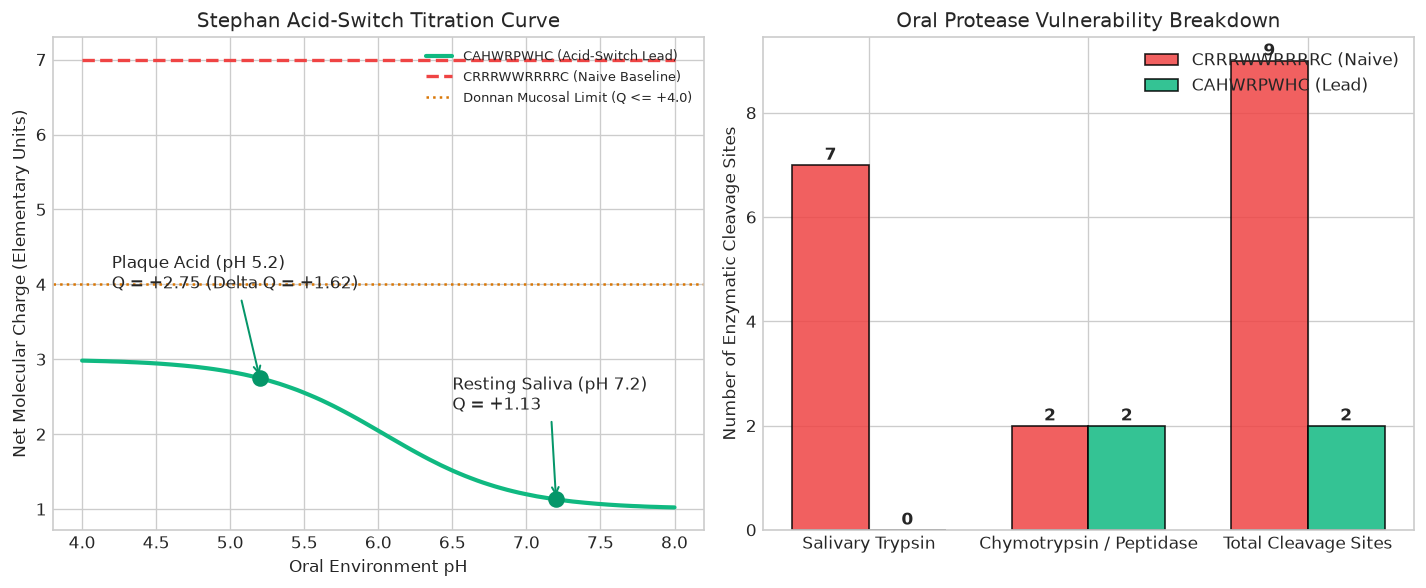

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Publication aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

repo_root = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()
sys.path.insert(0, str(repo_root))
from solubility_shield import calc_net_charge_at_ph, count_protease_cleavage_sites

# Calculate pH titration curves from pH 4.0 to 8.0
ph_range = np.linspace(4.0, 8.0, 100)
q_lead = [calc_net_charge_at_ph("CAHWRPWHC", ph) for ph in ph_range]
q_naive = [calc_net_charge_at_ph("CRRRWWRRRRC", ph) for ph in ph_range]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Panel 1: Stephan Charge Switch Titration
ax1.plot(ph_range, q_lead, color="#10b981", linewidth=2.5, label="CAHWRPWHC (Acid-Switch Lead)")
ax1.plot(ph_range, q_naive, color="#ef4444", linewidth=2.0, linestyle="--", label="CRRRWWRRRRC (Naive Baseline)")

# Mark Stephan transitions
q_72 = calc_net_charge_at_ph("CAHWRPWHC", 7.2)
q_52 = calc_net_charge_at_ph("CAHWRPWHC", 5.2)
delta_q = q_52 - q_72

ax1.scatter([7.2, 5.2], [q_72, q_52], color="#059669", s=80, zorder=5)
ax1.annotate(f"Resting Saliva (pH 7.2)\nQ = +{q_72:.2f}", xy=(7.2, q_72), xytext=(6.5, q_72 + 1.2),
             arrowprops=dict(arrowstyle="->", color="#059669", lw=1.2))
ax1.annotate(f"Plaque Acid (pH 5.2)\nQ = +{q_52:.2f} (Delta Q = +{delta_q:.2f})", xy=(5.2, q_52), xytext=(4.2, q_52 + 1.2),
             arrowprops=dict(arrowstyle="->", color="#059669", lw=1.2))

ax1.axhline(4.0, color="#d97706", linestyle=":", linewidth=1.5, label="Donnan Mucosal Limit (Q <= +4.0)")
ax1.set_xlabel("Oral Environment pH")
ax1.set_ylabel("Net Molecular Charge (Elementary Units)")
ax1.set_title("Stephan Acid-Switch Titration Curve")
ax1.legend(loc="upper right", fontsize=8)

# Panel 2: Protease Vulnerability Comparison
prot_lead = count_protease_cleavage_sites("CAHWRPWHC")
prot_naive = count_protease_cleavage_sites("CRRRWWRRRRC")

lead_total = len(prot_lead["trypsin_cleavage_sites"]) + prot_lead["chymotrypsin_site_count"]
naive_total = len(prot_naive["trypsin_cleavage_sites"]) + prot_naive["chymotrypsin_site_count"]

categories = ["Salivary Trypsin", "Chymotrypsin / Peptidase", "Total Cleavage Sites"]
lead_counts = [len(prot_lead["trypsin_cleavage_sites"]), prot_lead["chymotrypsin_site_count"], lead_total]
naive_counts = [len(prot_naive["trypsin_cleavage_sites"]), prot_naive["chymotrypsin_site_count"], naive_total]

x = np.arange(len(categories))
width = 0.35

ax2.bar(x - width/2, naive_counts, width, label="CRRRWWRRRRC (Naive)", color="#ef4444", edgecolor="black", alpha=0.85)
ax2.bar(x + width/2, lead_counts, width, label="CAHWRPWHC (Lead)", color="#10b981", edgecolor="black", alpha=0.85)

ax2.set_ylabel("Number of Enzymatic Cleavage Sites")
ax2.set_title("Oral Protease Vulnerability Breakdown")
ax2.set_xticks(x)
ax2.set_xticklabels(categories)
ax2.legend(loc="upper right")

for i, v in enumerate(naive_counts):
    ax2.text(i - width/2, v + 0.1, str(v), ha="center", fontweight="bold")
for i, v in enumerate(lead_counts):
    ax2.text(i + width/2, v + 0.1, str(v), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### Q&A
**Q1: Why does a charge surge at pH 5.2 help fight dental cavities?**  
*Answer:* Cavity-causing bacteria only damage teeth when fermenting sugar into acid below pH 5.5. The Stephan acid switch activates the peptide electrostatically exactly when and where acid damage is occurring, leaving neutral saliva unaffected.

**Q2: Is CAHWRPWHC completely resistant to oral digestion?**  
*Answer:* No. It is resistant to salivary trypsin due to the Arg5-Pro6 motif, but contains two aromatic residues (Trp4 and Trp7) vulnerable to salivary chymotrypsin and bacterial endopeptidases. It is classified as `AT_RISK` and requires whole-saliva half-life verification.

### Data Analysis Key Findings
- **Acid-Switch Mechanism:** Protonation of His3 and His8 generates an elementary charge surge of Delta Q = +1.62 between pH 7.2 and 5.2.
- **Donnan Clearance:** Net charge at pH 6.0 (+2.05) clears the +4.0 mucosal ceiling, preventing entrapment in chitosan nanoparticle carriers.
- **Protease Risk Identified:** Distinguishing trypsin resistance from chymotrypsin vulnerability prevents overconfident claims of metabolic immunity.

### Insights or Next Steps
- **Saliva Incubation:** Incubate synthetic `CAHWRPWHC` in pooled whole human saliva from healthy donors to quantify its real proteolytic half-life ($t_{1/2}$).

> [!NOTE]
> **Key Takeaway Box:** Candidate `CAHWRPWHC` survives tryptic digestion through the Arg5-Pro6 motif and delivers a +1.62 charge surge during cariogenic acid attacks. However, aromatic residues Trp4/Trp7 carry chymotryptic risk, classifying the candidate as `AT_RISK` and mandating whole-saliva testing.